# What is a Perceptron?

- It is an algorithm, just like Linear Regression, Logistic Regression, SVM..etc are algorithms.

- Used for supervised learning, which means it requires labeled data to learn from.

- Because of its design, it became buiding block of DL

- The design of perceptron:

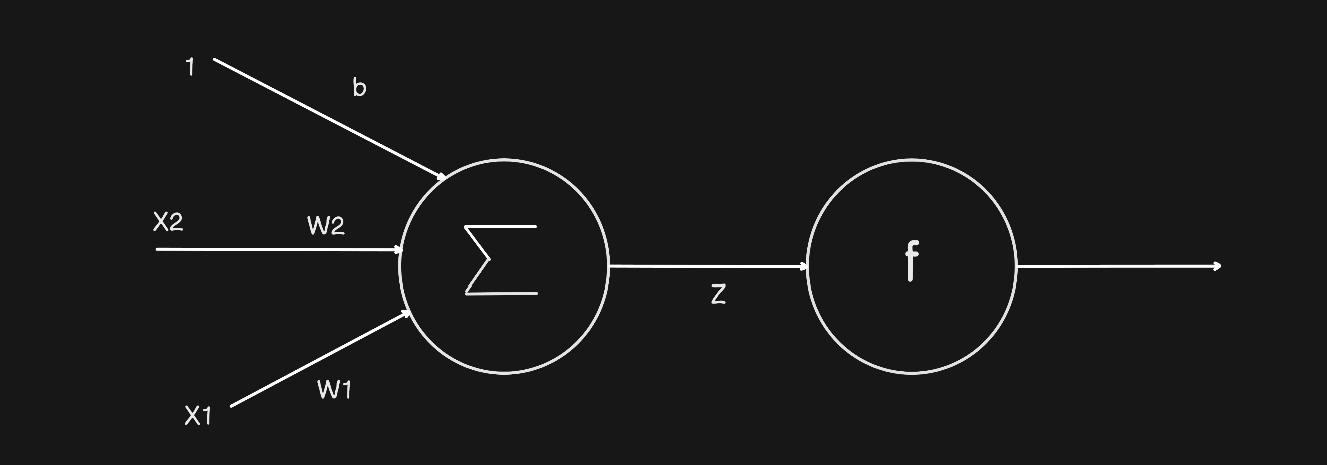

- Perceptron algorithm toh hai hi, saath hi saathe use hum ek **mathematical model/function** bol skte hai

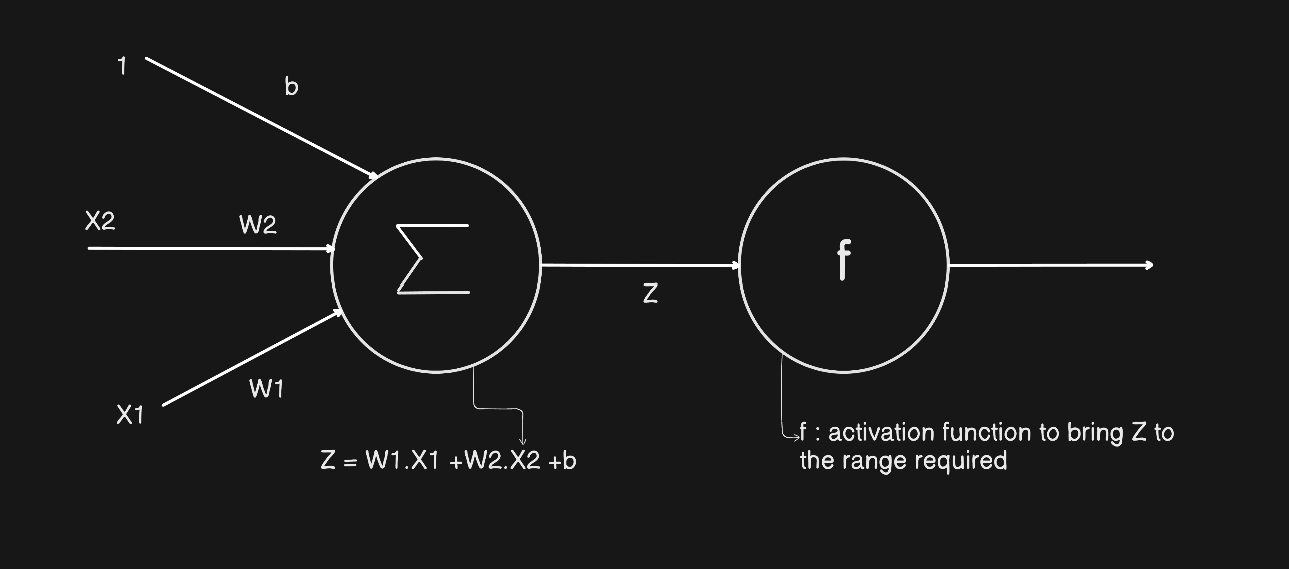

- $X_1, X_2$ are inputs features/columns

- $W_1, W_2$ are weights
- $b$ is the bias
- The work of activation function is to bring $Z$ to the desired output range
- Activation functions can be step function, sigmoid, ReLU, etc.

## How to use this design :

- Let say we have data with two features and a binary target variable.(Iq,cgpa and predicted placement status)

- So on giving any iq and cgpa valu, the model will predict the placement status of the student.

- If we want to solve it using a perceptron, there are 2 stages (jese ki kisi vhi ML alorithm me hota hai) :

    1. Training : We feed the iq and cgpa values along with the actual placement status to the model, and it learns the weights and bias that best fit the data.
    2. Prediction

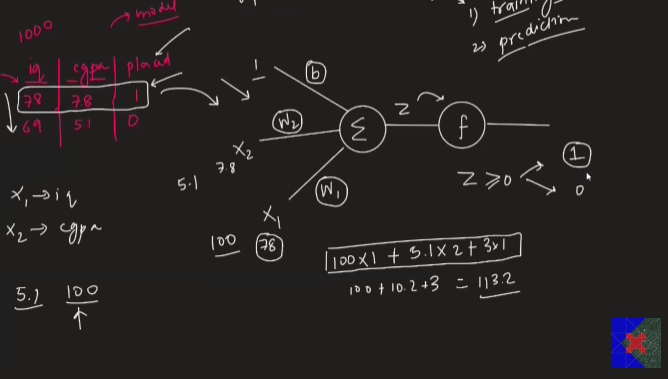

- Once the model is trained, we can use it to predict the placement status for new students by inputting their iq and cgpa values. The model will use the learned weights and bias to compute the output and apply the activation function to give us the predicted placement status.

- #### We will input the same number of X as the number of features in the data, similarly we will have the same number of weights as the number of features, and one bias term. 

- Deeplearning is heavily inspired by human nervous system

# Neuron V/S Perceptron

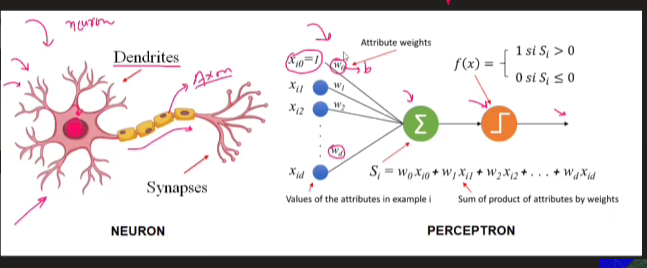

# Interpretation of weights

- Weights tell us which feature is more important factor in determining the output. Higher the weight, more important the feature.

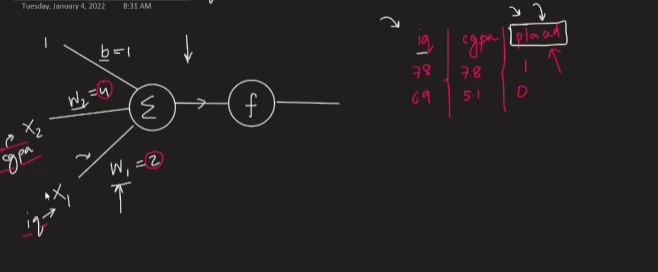

- In th above example weight corresponding to CGPA is higher than weight corresponding to IQ, which means CGPA is more important factor in determining the placement status of the student.

- Bias interpretation we will see in future lessons

# Geometric Intuition of perceptron

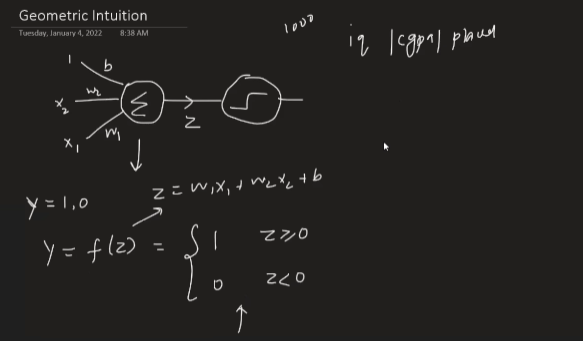

- So, perceptron is basically a function $y = f(w_1,x_1, w_2,x_2, ..., w_n,x_n, b)$

- Let's scatter plot the data points with IQ on x-axis and CGPA on y-axis, and green circle is for placed students and red circle is for not placed students.

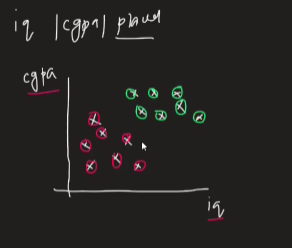

- Now we want to see how the alogorithm/perceptron/function is working on our data

- Notice a thing:

    - $ z = w_1*x_1 + w_2*x_2 + b $ is a equation of a line in 2D space

    - So our perceptron is basically learning a line that can separate the green circles from the red circles.

    - We are telling that if z is greater than 0, then the student is placed (the point lies in the green region), and if z is less than 0, then the student is not placed (the point lies in the red region).

- ### so perceptron is basically a line jiske madad se hum 2 region bana rhe hai, ek green region jisme placed students lie kr rhe hai, aur ek red region jisme not placed students lie kr rhe hai.

- ### <span style="color: orange;">**So, perceptron is basically a linear classifier.**</span>

- In 2D : it is a line, in 3D it will be a plane, and in higher dimensions it will be a hyperplane. But the concept is same, <span style="color: orange;">**it is a binary classifier that is trying to separate the data points into two classes using a linear decision boundary.**</span>

# Limitations of Perceptron:

- It can only solve linearly separable problems. If the data is not linearly separable, then the perceptron will not be able to find a decision boundary that can separate the classes.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
print(df.shape)
df.head()

(100, 3)


,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


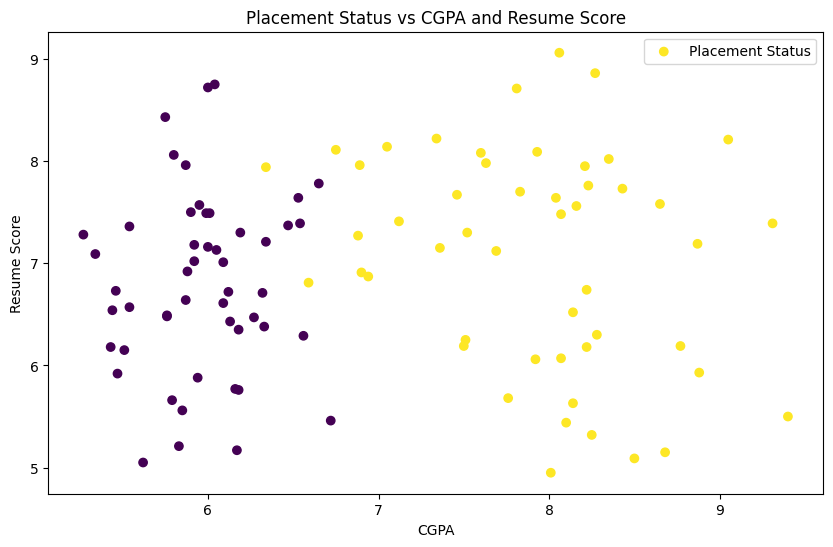

In [13]:
plt.figure(figsize=(10, 6))
plt.scatter(df['cgpa'], df['resume_score'], c=df['placed'], cmap='viridis', label='Placement Status')
plt.xlabel('CGPA')
plt.ylabel('Resume Score')
plt.title('Placement Status vs CGPA and Resume Score')
plt.legend()
plt.show()

In [6]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [7]:
from sklearn.linear_model import Perceptron
p = Perceptron()

In [8]:
p.fit(X,y)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary `.",0


In [9]:
p.coef_

array([[ 40.26, -36.  ]])

In [10]:
p.intercept_

array([-25.])

In [11]:
from mlxtend.plotting import plot_decision_regions

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

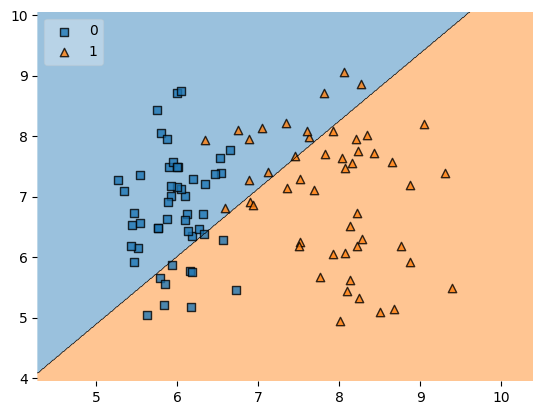

In [12]:
plot_decision_regions(X.values, y.values, clf=p, legend=2)

- Although you can see that it is not the best line, it is because we didn,t configure the perceptron properly, and also data is less

In [14]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

In [15]:
lr.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [17]:
lr.intercept_ , lr.coef_

(array([-26.4254774]), array([[3.30850543, 0.56672399]]))

In [18]:
m = lr.coef_[0][0] / lr.coef_[0][1]
c = lr.intercept_[0]

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


<Axes: >

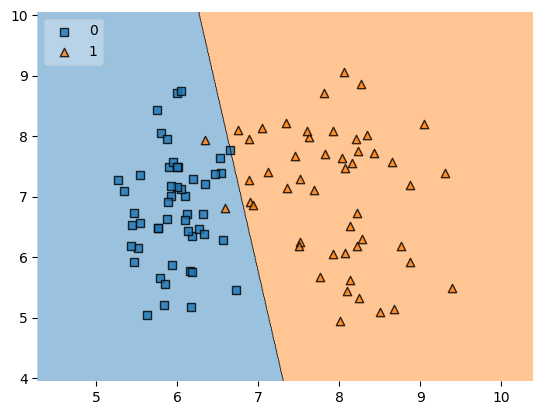

In [21]:
plot_decision_regions(X.values, y.values, clf=lr, legend=2)